In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

1. PROBLEM DEFINITION
Dataset: Breast Cancer Wisconsin
Problem type: Binary Classification
Features (X): 30 numeric tumor measurements
Target (y): Malignant = 1, Benign = 0
Goal: Predict whether a tumor is malignant or benign.

Dataset shape: (569, 30)

Target distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Training samples: 455
Testing samples: 114

2. MODEL COMPARISON TABLE


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.987,0.965,0.975,0.929,0.951
1,Random Forest,1.000,0.965,1.000,0.905,0.950
2,KNN,0.978,0.956,0.974,0.905,0.938
3,Decision Tree,0.987,0.921,0.946,0.833,0.886



3. CONFUSION MATRICES


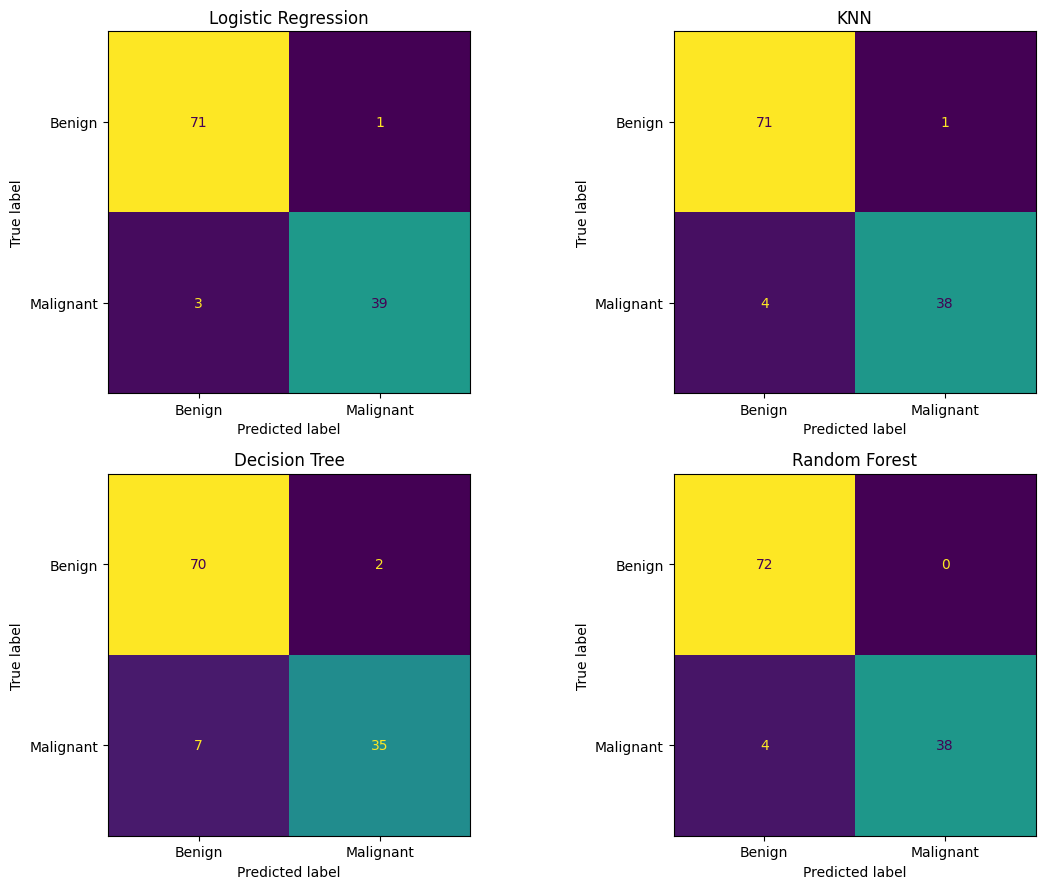


4. PERFORMANCE COMPARISON CHART


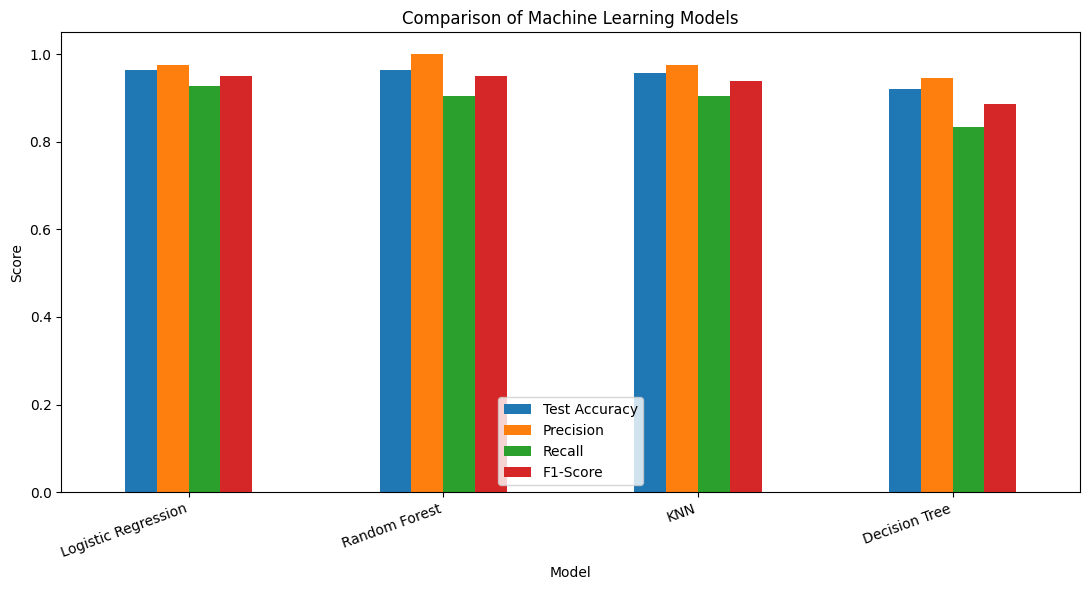


5. OVERFITTING AND UNDERFITTING CHECK


,Model,Train Accuracy,Test Accuracy,Train-Test Gap,Fit Assessment
0,Logistic Regression,0.987,0.965,0.022,No strong warning from accuracy alone
1,Random Forest,1.000,0.965,0.035,No strong warning from accuracy alone
2,KNN,0.978,0.956,0.022,No strong warning from accuracy alone
3,Decision Tree,0.987,0.921,0.066,No strong warning from accuracy alone



6. FINAL CONCLUSION
--------------------
Best model by malignant-class recall: Logistic Regression
Test Accuracy: 0.965
Precision: 0.975
Recall: 0.929
F1-Score: 0.951

Why use Recall?
Recall is important because a false negative means a malignant tumor was incorrectly predicted as benign.

Confusion Matrix Counts:
True Negatives: 71
False Positives: 1
False Negatives: 3
True Positives: 39

Overfitting / Underfitting:
No strong warning from accuracy alone

FINAL SUMMARY:
Logistic Regression was selected based on malignant-class recall, with F1-score and test accuracy used to break ties. The train-test accuracy gap provides a basic check for possible overfitting. Recall, precision, and the confusion matrix should also be examined before choosing a model.

Note: This is an educational experiment, not a medical diagnostic system.


In [1]:

# APPLY AND COMPARE MACHINE LEARNING MODELS
# Dataset: Breast Cancer Wisconsin
# Problem: Classification

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. DEFINE THE PROBLEM
print("1. PROBLEM DEFINITION")
print("Dataset: Breast Cancer Wisconsin")
print("Problem type: Binary Classification")
print("Features (X): 30 numeric tumor measurements")
print("Target (y): Malignant = 1, Benign = 0")
print("Goal: Predict whether a tumor is malignant or benign.")

# 2. LOAD DATA
data = load_breast_cancer(as_frame=True)
X = data.data

# Original dataset: 0 = malignant, 1 = benign
# Change target so malignant becomes 1
y = (data.target == 0).astype(int)

print("\nDataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))
display(X.head())

# 3. TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. CREATE FOUR MODELS
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

# 5. TRAIN AND EVALUATE
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    predictions[name] = test_prediction

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, train_prediction
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_prediction
        ),
        "Precision": precision_score(
            y_test, test_prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_prediction, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, test_prediction, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# 6. COMPARISON TABLE
print("\n2. MODEL COMPARISON TABLE")

results_df = results_df.sort_values(
    by=["Recall", "F1-Score", "Test Accuracy"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(3))

# 7. CONFUSION MATRICES
print("\n3. CONFUSION MATRICES")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, prediction) in zip(
    axes.ravel(), predictions.items()
):
    cm = confusion_matrix(
        y_test, prediction, labels=[0, 1]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    display_matrix.plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 8. PERFORMANCE CHART
print("\n4. PERFORMANCE COMPARISON CHART")

chart = results_df.set_index("Model")[
    ["Test Accuracy", "Precision", "Recall", "F1-Score"]
]

chart.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# 9. OVERFITTING / UNDERFITTING CHECK
print("\n5. OVERFITTING AND UNDERFITTING CHECK")

results_df["Train-Test Gap"] = (
    results_df["Train Accuracy"] -
    results_df["Test Accuracy"]
)

def check_fit(row):
    if row["Train-Test Gap"] > 0.10:
        return "Possible overfitting"
    elif (
        row["Train Accuracy"] < 0.80
        and row["Test Accuracy"] < 0.80
    ):
        return "Possible underfitting"
    else:
        return "No strong warning from accuracy alone"

results_df["Fit Assessment"] = results_df.apply(
    check_fit, axis=1
)

display(results_df[
    ["Model", "Train Accuracy", "Test Accuracy",
     "Train-Test Gap", "Fit Assessment"]
].round(3))

# 10. FINAL CONCLUSION
best = results_df.iloc[0]
best_name = best["Model"]
best_prediction = predictions[best_name]

tn, fp, fn, tp = confusion_matrix(
    y_test, best_prediction, labels=[0, 1]
).ravel()

print("\n6. FINAL CONCLUSION")
print("--------------------")
print("Best model by malignant-class recall:", best_name)
print(f"Test Accuracy: {best['Test Accuracy']:.3f}")
print(f"Precision: {best['Precision']:.3f}")
print(f"Recall: {best['Recall']:.3f}")
print(f"F1-Score: {best['F1-Score']:.3f}")

print("\nWhy use Recall?")
print(
    "Recall is important because a false negative means "
    "a malignant tumor was incorrectly predicted as benign."
)

print("\nConfusion Matrix Counts:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nOverfitting / Underfitting:")
print(best["Fit Assessment"])

print("\nFINAL SUMMARY:")
print(
    f"{best_name} was selected based on malignant-class recall, "
    "with F1-score and test accuracy used to break ties. "
    "The train-test accuracy gap provides a basic check for "
    "possible overfitting. Recall, precision, and the confusion "
    "matrix should also be examined before choosing a model."
)

print(
    "\nNote: This is an educational experiment, not a medical "
    "diagnostic system."
)
